In [78]:
!pip install rdkit

In [79]:
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, AllChem, rdFingerprintGenerator
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

In [80]:
path = ('/content/delaney.csv')

In [81]:
df = pd.read_csv(path)
df

,Compound ID,measured log(solubility:mol/L),ESOL predicted log(solubility:mol/L),SMILES
0,"1,1,1,2-Tetrachloroethane",-2.180,-2.794,ClCC(Cl)(Cl)Cl
1,"1,1,1-Trichloroethane",-2.000,-2.232,CC(Cl)(Cl)Cl
2,"1,1,2,2-Tetrachloroethane",-1.740,-2.549,ClC(Cl)C(Cl)Cl
3,"1,1,2-Trichloroethane",-1.480,-1.961,ClCC(Cl)Cl
4,"1,1,2-Trichlorotrifluoroethane",-3.040,-3.077,FC(F)(Cl)C(F)(Cl)Cl
...,...,...,...,...
1139,vamidothion,1.144,-1.446,CNC(=O)C(C)SCCSP(=O)(OC)(OC)
1140,Vinclozolin,-4.925,-4.377,CC1(OC(=O)N(C1=O)c2cc(Cl)cc(Cl)c2)C=C
1141,Warfarin,-3.893,-3.913,CC(=O)CC(c1ccccc1)c3c(O)c2ccccc2oc3=O
1142,Xipamide,-3.790,-3.642,Cc1cccc(C)c1NC(=O)c2cc(c(Cl)cc2O)S(N)(=O)=O


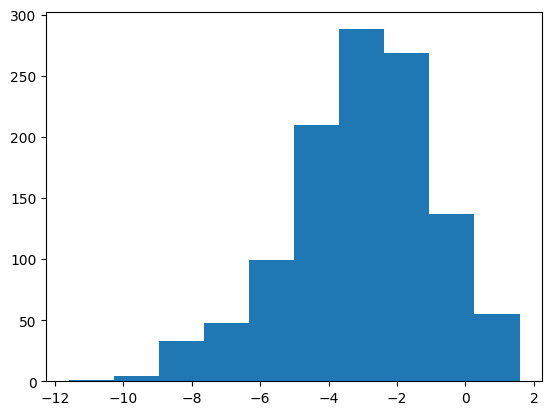

In [82]:
plt.hist(df['measured log(solubility:mol/L)'])
plt.show()

In [83]:
def calculate_delaney_descriptors(smiles_list):
    feats_list = []
    for smiles in smiles_list:
        mol = Chem.MolFromSmiles(smiles)
        logp = Descriptors.MolLogP(mol)
        mw = Descriptors.MolWt(mol)
        num_rot_bonds = Descriptors.NumRotatableBonds(mol)

        aromatic_atoms = sum(1 for atom in mol.GetAtoms() if atom.GetIsAromatic())
        heavy_atoms = mol.GetNumHeavyAtoms()
        aromatic_proportion = aromatic_atoms / heavy_atoms if heavy_atoms > 0 else 0

        feats_list.append({
            'MolLogP': logp,
            'MolWt': mw,
            'NumRotatableBonds': num_rot_bonds,
            'AromaticProportion': aromatic_proportion
        })
    return pd.DataFrame(feats_list)

In [84]:
X = calculate_delaney_descriptors(df['SMILES'])
y = df['measured log(solubility:mol/L)']

In [85]:
X

,MolLogP,MolWt,NumRotatableBonds,AromaticProportion
0,2.59540,167.850,0,0.000000
1,2.37650,133.405,0,0.000000
2,2.59380,167.850,1,0.000000
3,2.02890,133.405,1,0.000000
4,2.91890,187.375,1,0.000000
...,...,...,...,...
1139,1.98820,287.343,8,0.000000
1140,3.42130,286.114,2,0.333333
1141,3.60960,308.333,4,0.695652
1142,2.56214,354.815,3,0.521739


In [86]:
def train_RFRmodel(X, y):
  X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
  )
  rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
  rf_model.fit(X_train, y_train)
  y_train_pred = rf_model.predict(X_train)
  y_test_pred = rf_model.predict(X_test)
  test_r2 = r2_score(y_test, y_test_pred)
  test_mse = mean_squared_error(y_test, y_test_pred)
  result = {'y_test':y_test,
            'y_train_pred': y_train_pred,
            'y_test_pred': y_test_pred,
            'test_r2': test_r2,
            'test_mse': test_mse}
  return result

In [87]:
result = train_RFRmodel(X,y)
print(f'R2: {round(result['test_r2'], 2)}')
print(f'MSE: {round(result['test_mse'], 2)}')

R2: 0.89
MSE: 0.48


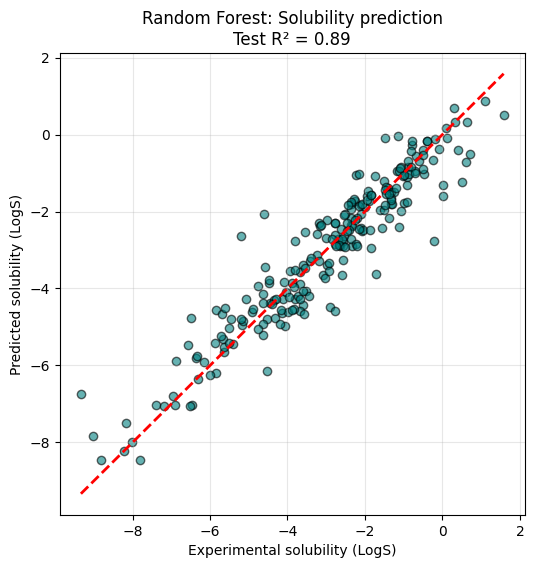

In [88]:
def pred_vs_exp_plot(y_test, y_test_pred, test_r2):
  plt.figure(figsize=(6, 6))
  plt.scatter(y_test, y_test_pred, alpha=0.6, color='teal', edgecolors='k')

  min_val = min(y_test.min(), y_test_pred.min())
  max_val = max(y_test.max(), y_test_pred.max())
  plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', lw=2)

  plt.xlabel('Experimental solubility (LogS)')
  plt.ylabel('Predicted solubility (LogS)')
  plt.title(f'Random Forest: Solubility prediction\nTest R² = {test_r2:.2f}')
  plt.grid(True, alpha=0.3)
  plt.savefig("pred_vs_exp.png", dpi=200)
  plt.show()
pred_vs_exp_plot(result['y_test'], result['y_test_pred'], result['test_r2'])

In [89]:
from sklearn.model_selection import cross_val_score

def train_and_evaluate_rfr(X, y, cv = 5):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )
    rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
    rf_model.fit(X_train, y_train)

    y_test_pred = rf_model.predict(X_test)
    test_r2 = r2_score(y_test, y_test_pred)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

    cv_r2_scores = cross_val_score(rf_model, X_train, y_train, cv=cv, scoring='r2')
    cv_mse_scores = cross_val_score(rf_model, X_train, y_train, cv=cv, scoring='neg_mean_squared_error')
    cv_rmse_scores = np.sqrt(-cv_mse_scores)

    return {
        'model': rf_model,
        'y_test': y_test,
        'y_test_pred': y_test_pred,
        'test_r2': test_r2,
        'test_rmse': test_rmse,
        'cv_r2_mean': cv_r2_scores.mean(),
        'cv_r2_std': cv_r2_scores.std(),
        'cv_rmse_mean': cv_rmse_scores.mean()
    }

results = train_and_evaluate_rfr(X, y)

print(f"Mean CV R²:   {results['cv_r2_mean']:.3f} (± {results['cv_r2_std']:.3f})")
print(f"Mean CV RMSE: {results['cv_rmse_mean']:.3f}\n")

print(f"Test R²:      {results['test_r2']:.3f}")
print(f"Test RMSE:    {results['test_rmse']:.3f}")


Mean CV R²:   0.870 (± 0.012)
Mean CV RMSE: 0.753

Test R²:      0.890
Test RMSE:    0.692


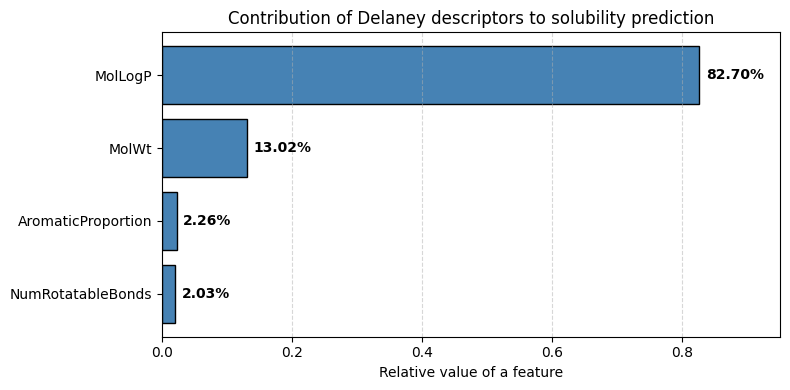

In [90]:
def plot_feature_importance(model, feature_names):
    importances = model.feature_importances_

    df_imp = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importances
    }).sort_values(by='Importance', ascending=True)

    plt.figure(figsize=(8, 4))
    bars = plt.barh(df_imp['Feature'], df_imp['Importance'], color='steelblue', edgecolor='black')

    for bar in bars:
        width = bar.get_width()
        plt.text(width + 0.01, bar.get_y() + bar.get_height()/2,
                 f'{width:.2%}', va='center', fontsize=10, fontweight='bold')

    plt.xlim(0, max(importances) * 1.15)
    plt.xlabel('Relative value of a feature')
    plt.title('Contribution of Delaney descriptors to solubility prediction')
    plt.grid(axis='x', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.savefig("feature_importance.png", dpi=200)
    plt.show()

plot_feature_importance(results['model'], X.columns)


In [91]:
def predict_new_molecule(smiles, model):
    features_df = calculate_delaney_descriptors([smiles])
    predicted_logs = model.predict(features_df)[0]
    return predicted_logs

trained_model = results['model']
for name, smiles in test_molecules:
    predict_new_molecule(smiles, trained_model)


In [92]:
test_molecules = [
    ("Caffeine", "CN1C=NC2=C1C(=O)N(C(=O)N2C)C"),
    ("Aspirin", "CC(=O)OC1=CC=CC=C1C(=O)O"),
    ("Paracetamol", "CC(=O)NC1=CC=C(C=C1)O"),
    ("Ibuprofen", "CC(C)CC1=CC=C(C=C1)C(C)C(=O)O"),
    ("Cholesterol", "CC(C)CCCC(C)C1CCC2C1(CCC3C2CC=C4C3(CCC(C4)O)C)C")
]
columns = ["Compound", "SMILES",]
new_molecules_predictions = pd.DataFrame(test_molecules, columns = columns)
log_s = []
for smiles in new_molecules_predictions["SMILES"]:
  log_s.append(predict_new_molecule(smiles, trained_model))
new_molecules_predictions["Predicted log S"] = log_s
new_molecules_predictions

,Compound,SMILES,Predicted log S
0,Caffeine,CN1C=NC2=C1C(=O)N(C(=O)N2C)C,-1.466810
1,Aspirin,CC(=O)OC1=CC=CC=C1C(=O)O,-2.022647
2,Paracetamol,CC(=O)NC1=CC=C(C=C1)O,-1.337860
3,Ibuprofen,CC(C)CC1=CC=C(C=C1)C(C)C(=O)O,-3.227718
4,Cholesterol,CC(C)CCCC(C)C1CCC2C1(CCC3C2CC=C4C3(CCC(C4)O)C)C,-7.333376
